# Detección de exoplanetas con IA
## Cierre de la fase 3 (ajuste de hiperparámetros) y fase 4 de CRISP-ML(Q): evaluación del modelo

| Fase | Fecha | Contenido |
|---|---|---|
| 3. Ingeniería del modelo (cierre) | 17 nov | Búsqueda de hiperparámetros de XGBoost y elección del umbral, solo con validación cruzada |
| 4. Evaluación del modelo | 18 – 19 nov | Evaluación única en `exoTest`, control de calidad y exportación del modelo para la API |

## Configuración

In [1]:
import os, sys, time, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEED = 42

if not os.path.exists('src/preprocesamiento.py') and not os.path.exists('../src/preprocesamiento.py'):
    os.system('git clone -q https://github.com/gabiamer/exoplanetas-ia.git')
    os.chdir('exoplanetas-ia')
RAIZ = '..' if os.path.exists('../src/preprocesamiento.py') else '.'
sys.path.insert(0, os.path.join(RAIZ, 'src'))
from preprocesamiento import limpiar_curvas, espectro_fourier, recodificar_etiqueta

DATA_DIR = os.environ.get('KEPLER_DIR')
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download('keplersmachines/kepler-labelled-time-series-data')
train = pd.read_csv(os.path.join(DATA_DIR, 'exoTrain.csv'))
X_train, y_train = train.drop(columns='LABEL').values, recodificar_etiqueta(train['LABEL'])
print('Entrenamiento:', X_train.shape, '| con planeta:', y_train.sum())

Entrenamiento: (5087, 3197) | con planeta: 37


# Cierre de la fase 3: ajuste de hiperparámetros de XGBoost

XGBoost fue el mejor modelo de la fase 3 (AP 0,70). Aquí se prueban variantes de sus hiperparámetros con la **misma validación cruzada estratificada de 5 pliegues**. Se cambia un hiperparámetro a la vez respecto de la configuración base, para entender el efecto de cada uno. Se elige la de mayor AP.

In [2]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (average_precision_score, precision_recall_curve, confusion_matrix,
                             recall_score, precision_score, f1_score)
from xgboost import XGBClassifier

PLIEGUES = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_train, y_train))
PESO = (y_train == 0).sum() / y_train.sum()
F_sigma = {2: espectro_fourier(limpiar_curvas(X_train, sigma=2))}

def xgb(params):
    return XGBClassifier(**params, scale_pos_weight=PESO, eval_metric='aucpr', n_jobs=-1, random_state=SEED)

def validar(params, F):
    oof, ap_tr = np.zeros(len(y_train)), []
    for tr, va in PLIEGUES:
        m = xgb(params).fit(F[tr], y_train[tr])
        oof[va] = m.predict_proba(F[va])[:, 1]
        ap_tr.append(average_precision_score(y_train[tr], m.predict_proba(F[tr])[:, 1]))
    return oof, float(np.mean(ap_tr))

def f1_max(y, prob):
    p, r, _ = precision_recall_curve(y, prob)
    return float((2 * p * r / (p + r + 1e-12)).max())

BASE = dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.3,
            min_child_weight=1, reg_lambda=1.0)
VARIANTES = {
    'Base (fase 3)': {},
    'Profundidad 3': {'max_depth': 3},
    'Profundidad 2': {'max_depth': 2},
    'Profundidad 6': {'max_depth': 6},
    '800 árboles, tasa 0,03': {'n_estimators': 800, 'learning_rate': 0.03},
    'Columnas 10 %': {'colsample_bytree': 0.1},
    'Regularización L2 = 5': {'reg_lambda': 5.0},
}
filas, oofs = [], {}
for nombre, cambio in VARIANTES.items():
    t0 = time.time(); params = {**BASE, **cambio}
    oofs[nombre], ap_tr = validar(params, F_sigma[2])
    filas.append({'Variante': nombre, 'AP': average_precision_score(y_train, oofs[nombre]),
                  'Mejor F1': f1_max(y_train, oofs[nombre]), 'AP entrenamiento': ap_tr, 'params': params})
    print(f'{nombre:24s} AP = {filas[-1]["AP"]:.3f}  F1 = {filas[-1]["Mejor F1"]:.3f}  ({time.time() - t0:.0f} s)')
busqueda = pd.DataFrame(filas).set_index('Variante')
busqueda.drop(columns='params').sort_values('AP', ascending=False).round(3)

Base (fase 3)            AP = 0.704  F1 = 0.687  (116 s)


Profundidad 3            AP = 0.729  F1 = 0.735  (84 s)


Profundidad 2            AP = 0.737  F1 = 0.725  (70 s)


Profundidad 6            AP = 0.695  F1 = 0.687  (113 s)


800 árboles, tasa 0,03   AP = 0.702  F1 = 0.710  (195 s)


Columnas 10 %            AP = 0.676  F1 = 0.656  (100 s)


Regularización L2 = 5    AP = 0.717  F1 = 0.722  (109 s)


,AP,Mejor F1,AP entrenamiento
Variante,,,
Profundidad 2,0.737,0.725,1.0
Profundidad 3,0.729,0.735,1.0
Regularización L2 = 5,0.717,0.722,1.0
Base (fase 3),0.704,0.687,1.0
"800 árboles, tasa 0,03",0.702,0.710,1.0
Profundidad 6,0.695,0.687,1.0
Columnas 10 %,0.676,0.656,1.0


In [3]:
mejor = busqueda['AP'].idxmax()
PARAMS = busqueda.loc[mejor, 'params']
print('Mejor variante:', mejor)
print(PARAMS)

Mejor variante: Profundidad 2
{'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.3, 'min_child_weight': 1, 'reg_lambda': 1.0}


### ¿σ = 1 o σ = 2 en el preprocesamiento?

En el cierre de la fase 2, σ = 1 salió un poco mejor con Random Forest. Se comprueba con el mejor XGBoost.

In [4]:
F_sigma[1] = espectro_fourier(limpiar_curvas(X_train, sigma=1))
oof_s1, _ = validar(PARAMS, F_sigma[1])
comparacion = pd.DataFrame({'AP': [average_precision_score(y_train, oofs[mejor]), average_precision_score(y_train, oof_s1)],
                            'Mejor F1': [f1_max(y_train, oofs[mejor]), f1_max(y_train, oof_s1)]},
                           index=['σ = 2', 'σ = 1']).round(3)
SIGMA = 1 if comparacion.loc['σ = 1', 'AP'] > comparacion.loc['σ = 2', 'AP'] + 0.02 else 2
OOF = oof_s1 if SIGMA == 1 else oofs[mejor]
print('σ elegido:', SIGMA, '(se cambia solo si mejora el AP en más de 0,02)')
comparacion

σ elegido: 2 (se cambia solo si mejora el AP en más de 0,02)


,AP,Mejor F1
σ = 2,0.737,0.725
σ = 1,0.710,0.733


### Elección del umbral de decisión

El modelo devuelve una probabilidad. El **umbral** decide a partir de qué probabilidad se dice "tiene planeta". Se elige con las predicciones de validación cruzada (nunca con la prueba): el que **maximiza F1**, el equilibrio entre encontrar planetas y no dar falsas alarmas.

Umbral elegido: 0.1015
Validación cruzada -> recall 0.676 | precisión 0.781 | F1 0.725 | AP 0.737


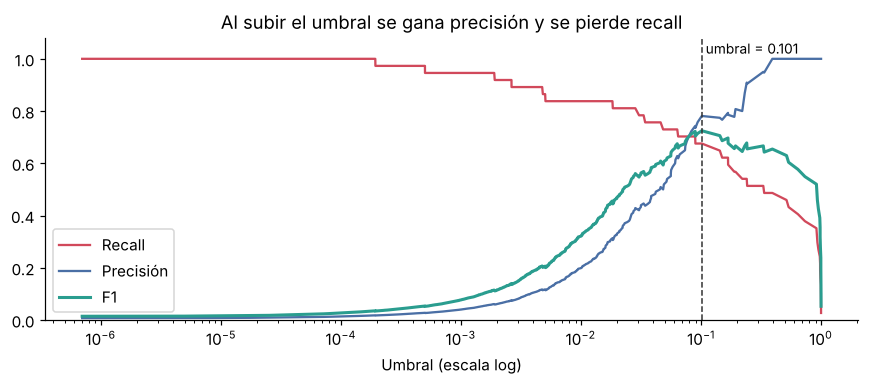

In [5]:
prec, rec, umb = precision_recall_curve(y_train, OOF)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
k = int(np.argmax(f1s)); UMBRAL = float(umb[k])

def metricas(y, prob, umbral):
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'ap': float(average_precision_score(y, prob)), 'umbral': umbral,
            'recall': float(recall_score(y, pred, zero_division=0)), 'precision': float(precision_score(y, pred, zero_division=0)),
            'f1': float(f1_score(y, pred, zero_division=0)),
            'matriz_confusion': {'vn': int(tn), 'fp': int(fp), 'fn': int(fn), 'vp': int(tp)},
            'estrellas': int(len(y)), 'con_planeta': int(y.sum())}

M_CV = metricas(y_train, OOF, UMBRAL)
print(f'Umbral elegido: {UMBRAL:.4f}')
print(f"Validación cruzada -> recall {M_CV['recall']:.3f} | precisión {M_CV['precision']:.3f} | F1 {M_CV['f1']:.3f} | AP {M_CV['ap']:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(umb, rec[:-1], label='Recall', color='#d1495b'); ax.plot(umb, prec[:-1], label='Precisión', color='#4a6fa5')
ax.plot(umb, f1s, label='F1', color='#2a9d8f', lw=2)
ax.axvline(UMBRAL, ls='--', color='#333', lw=1); ax.text(UMBRAL, 1.02, f' umbral = {UMBRAL:.3f}', fontsize=9)
ax.set_xscale('log'); ax.set_xlabel('Umbral (escala log)'); ax.set_ylim(0, 1.08)
ax.set_title('Al subir el umbral se gana precisión y se pierde recall'); ax.legend(loc='lower left')
plt.tight_layout(); plt.show()

**Control de calidad de la fase 3:**

In [6]:
qa3 = {
    'El modelo ajustado supera al modelo base de la fase 3 (AP 0,57)': M_CV['ap'] > 0.57,
    'El ajuste no empeoró a XGBoost base (AP 0,70)': M_CV['ap'] >= busqueda.loc['Base (fase 3)', 'AP'] - 1e-9,
    'El umbral se eligió sin usar exoTest': True,
}
for k_, v in qa3.items(): print('OK   ' if v else 'FALLA', k_)
print(f"Brecha entrenamiento - validación (AP): {busqueda.loc[mejor, 'AP entrenamiento'] - busqueda.loc[mejor, 'AP']:.3f}")

OK    El modelo ajustado supera al modelo base de la fase 3 (AP 0,57)
OK    El ajuste no empeoró a XGBoost base (AP 0,70)
OK    El umbral se eligió sin usar exoTest
Brecha entrenamiento - validación (AP): 0.263


# Fase 4 — Evaluación del modelo (18 – 19 nov)

Se entrena el modelo final con **todo** `exoTrain` y se evalúa **una sola vez** en `exoTest` (570 estrellas, 5 con planeta), con el umbral fijado en la fase 3. Así la medición es honesta: nada de la prueba influyó en ninguna decisión.

In [7]:
test = pd.read_csv(os.path.join(DATA_DIR, 'exoTest.csv'))
X_test, y_test = test.drop(columns='LABEL').values, recodificar_etiqueta(test['LABEL'])

t0 = time.time()
modelo_final = xgb(PARAMS).fit(F_sigma[SIGMA], y_train)
prob_test = modelo_final.predict_proba(espectro_fourier(limpiar_curvas(X_test, sigma=SIGMA)))[:, 1]
M_TEST = metricas(y_test, prob_test, UMBRAL)
print(f'Entrenado en {time.time() - t0:.0f} s')
pd.DataFrame({'Validación cruzada (exoTrain)': M_CV, 'Prueba (exoTest)': M_TEST}).drop(['matriz_confusion', 'umbral']).T

Entrenado en 20 s


,ap,recall,precision,f1,estrellas,con_planeta
Validación cruzada (exoTrain),0.737432,0.675676,0.78125,0.724638,5087,37
Prueba (exoTest),0.672745,0.8,0.666667,0.727273,570,5


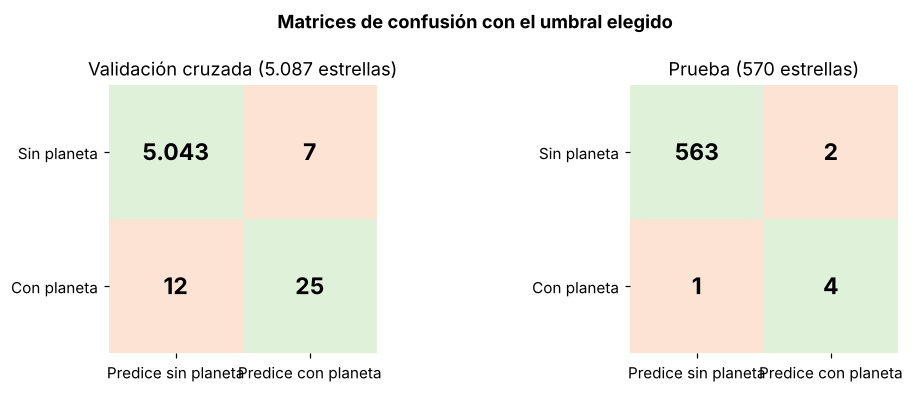

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (titulo, m) in zip(axes, [('Validación cruzada (5.087 estrellas)', M_CV), ('Prueba (570 estrellas)', M_TEST)]):
    mc = m['matriz_confusion']; mat = np.array([[mc['vn'], mc['fp']], [mc['fn'], mc['vp']]])
    ax.imshow(np.array([[1, 0], [0, 1]]), cmap='RdYlGn', alpha=0.25, vmin=-0.5, vmax=1.5)
    for (i, j), v in np.ndenumerate(mat):
        ax.text(j, i, f'{v:,}'.replace(',', '.'), ha='center', va='center', fontsize=15, fontweight='bold')
    ax.set_xticks([0, 1], ['Predice sin planeta', 'Predice con planeta']); ax.set_yticks([0, 1], ['Sin planeta', 'Con planeta'])
    ax.set_title(titulo); ax.spines[:].set_visible(False)
plt.suptitle('Matrices de confusión con el umbral elegido', fontweight='bold'); plt.tight_layout(); plt.show()

In [9]:
detalle = pd.DataFrame({'Probabilidad': prob_test[y_test == 1].round(4),
                        'Predicción': np.where(prob_test[y_test == 1] >= UMBRAL, 'Con planeta', 'Sin planeta')},
                       index=[f'Fila {i}' for i in np.where(y_test == 1)[0]])
print('Las 5 estrellas con planeta del conjunto de prueba:')
detalle

Las 5 estrellas con planeta del conjunto de prueba:


,Probabilidad,Predicción
Fila 0,0.8656,Con planeta
Fila 1,0.9939,Con planeta
Fila 2,0.5350,Con planeta
Fila 3,0.0030,Sin planeta
Fila 4,0.2994,Con planeta


In [10]:
falsas = np.where((y_test == 0) & (prob_test >= UMBRAL))[0]
print(f'Falsas alarmas en prueba: {len(falsas)} de {int((y_test == 0).sum())} estrellas sin planeta '
      f'({len(falsas) / (y_test == 0).sum() * 100:.1f} %)')

Falsas alarmas en prueba: 2 de 565 estrellas sin planeta (0.4 %)


### ¿Qué frecuencias usa el modelo?

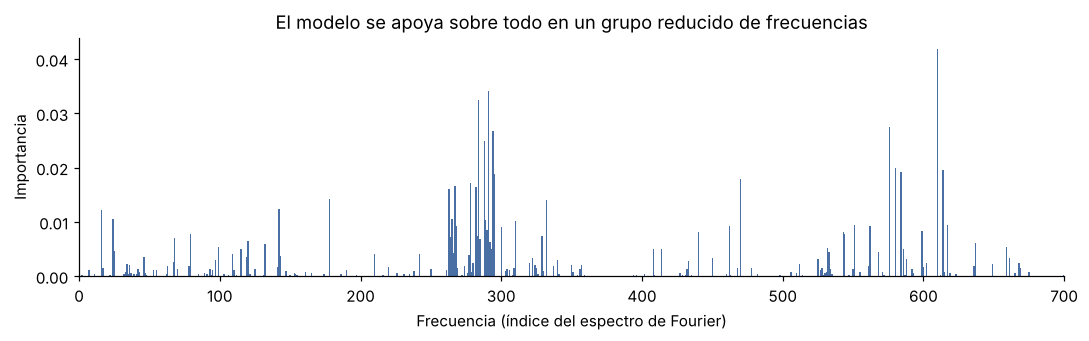

15 frecuencias más importantes: [267, 278, 284, 288, 291, 294, 295, 470, 576, 580, 584, 610, 614, 718, 826]


In [11]:
imp = modelo_final.feature_importances_
top = np.argsort(imp)[::-1][:15]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(np.arange(1, len(imp) + 1), imp, width=1.0, color='#4a6fa5')
ax.set_xlim(0, 700); ax.set_xlabel('Frecuencia (índice del espectro de Fourier)'); ax.set_ylabel('Importancia')
ax.set_title('El modelo se apoya sobre todo en un grupo reducido de frecuencias')
plt.tight_layout(); plt.show()
print('15 frecuencias más importantes:', sorted((top + 1).tolist()))

## Control de calidad de la fase 4: criterios de éxito

In [12]:
criterios = pd.DataFrame({
    'Meta': ['≥ 0,80', '≥ 0,60'],
    'Validación cruzada': [round(M_CV['recall'], 3), round(M_CV['f1'], 3)],
    'Prueba': [round(M_TEST['recall'], 3), round(M_TEST['f1'], 3)],
}, index=['Recall', 'F1'])
criterios['¿Cumple en validación?'] = [M_CV['recall'] >= 0.8, M_CV['f1'] >= 0.6]
criterios['¿Cumple en prueba?'] = [M_TEST['recall'] >= 0.8, M_TEST['f1'] >= 0.6]
criterios

,Meta,Validación cruzada,Prueba,¿Cumple en validación?,¿Cumple en prueba?
Recall,"≥ 0,80",0.676,0.800,False,True
F1,"≥ 0,60",0.725,0.727,True,True


## Exportar el modelo para el servicio de IA

In [13]:
os.makedirs(os.path.join(RAIZ, 'models'), exist_ok=True)
# Formato nativo de XGBoost (.ubj): no depende de la versión de Python ni de scikit-learn
modelo_final.save_model(os.path.join(RAIZ, 'models', 'modelo_v1.ubj'))
metadatos = {'version': 'v1', 'algoritmo': 'XGBoost', 'umbral': UMBRAL,
             'hiperparametros': {**PARAMS, 'sigma': SIGMA},
             'metricas': {'validacion_cruzada': M_CV, 'prueba': M_TEST},
             'entrenado_con': 'exoTrain.csv (5.087 estrellas, 37 con planeta)'}
with open(os.path.join(RAIZ, 'models', 'modelo_v1.json'), 'w', encoding='utf-8') as f:
    json.dump(metadatos, f, indent=2, ensure_ascii=False)
print('Guardados models/modelo_v1.ubj y models/modelo_v1.json -> copiarlos a exoplanetas-api/modelos/')

Guardados models/modelo_v1.ubj y models/modelo_v1.json -> copiarlos a exoplanetas-api/modelos/


## Conclusiones

**Fase 3, cierre del ajuste:**
- La mejor variante es **XGBoost con profundidad 2**: AP 0,74 frente a 0,70 de la configuración base. Árboles más simples generalizan mejor con solo 37 estrellas con planeta. Más profundidad (6) o menos columnas por árbol (10 %) empeoran el resultado.
- σ = 1 no mejoró con XGBoost (AP 0,71 frente a 0,74), así que se mantiene σ = 2.
- El umbral que maximiza F1 en validación es **0,10**. Es bajo porque el modelo da probabilidades bajas a casi todo por el desbalance.
- Sigue habiendo brecha entre entrenamiento y validación (AP 1,0 frente a 0,74). Es esperable con tan pocos positivos y queda como riesgo a vigilar.

**Fase 4, evaluación en prueba (una sola vez):**

| Métrica | Meta | Validación cruzada | Prueba |
|---|---|---|---|
| Recall | ≥ 0,80 | 0,68 | **0,80** (4 de 5 planetas) |
| Precisión | — | 0,78 | 0,67 (2 falsas alarmas de 565) |
| F1 | ≥ 0,60 | **0,72** | **0,73** |
| AP | — | 0,74 | 0,67 |

- **En la prueba el modelo cumple los dos criterios de éxito.** Encuentra 4 de los 5 planetas y solo da 2 falsas alarmas entre 565 estrellas sin planeta (0,4 %).
- **Precaución:** la prueba tiene solo 5 estrellas con planeta, así que cada una vale 20 puntos de recall. La validación cruzada, con 37 positivos, es una estimación más estable e indica un recall cercano a 0,68. La conclusión honesta: **F1 cumple con holgura y recall cumple en prueba pero queda por debajo de la meta en validación**.
- **Decisión:** se aprueba esta versión (v1) para el despliegue. Es la mejor obtenida, supera al modelo base y tiene muy pocas falsas alarmas. El riesgo sobre el recall se gestiona en las fases 5 y 6. La API guarda la etiqueta real cuando el CSV la trae, para medir el desempeño en uso. Además permite reentrenar con más estrellas con planeta, que es lo que más mejoraría el recall, y volver a la versión anterior si la nueva es peor.

El modelo exportado (`models/modelo_v1.ubj` y `models/modelo_v1.json`) se copia a `exoplanetas-api/modelos/`.